# 02 — Fully Pre-Trained Model

## Let's use a pre-existing model that was pre-trained, as is, with no fine-tuning! Meaning, let's see how good an off-the-shelf, ready-made-model can do on our task.

## Steps

1. Select a pretrained Monet-style generator.
- Original authors’ Monet-style PyTorch checkpoint is a possibility. It fits the task and our framework.
2. Verify that it translates photos into paintings. Does it do photo-to-Monet?
3. Check its required architecture and image preprocessing.
4. Check compatibility with our PyTorch environment.
5. Load the model and test one photo.
6. Display the original photo and generated painting side by side.

## Use Original authors’ Monet-style PyTorch checkpoint

In [9]:
# standard library
from io import BytesIO
from pathlib import Path
import random
import sys
import time
from zipfile import ZipFile, ZIP_STORED

# third-party
import matplotlib.pyplot as plt
from PIL import Image
import torch

# local
project_root = Path.cwd()
if not (project_root / "scripts").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "scripts"))

from painter_dataset_config import DATA_DIR
from painter_pretrained_helpers import load_pretrained_generator, translate_photo

## Pretrained baseline: photo → Monet

Use the authors' **style_monet** checkpoint as supplied: no training, fine-tuning, optimizer, or weight updates.
- USED: Their [model zoo](https://github.com/junyanz/CycleGAN#model-zoo) identifies style_monet as landscape-photo-to-Monet; 
- NOT USED: `monet2photo` is the reverse direction. 
- The [official downloader](https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix/blob/master/scripts/download_cyclegan_model.sh) supplies the checkpoint URL.

## Re-using/Adapting Code from the Original Authors

### We reuse the authors' [ResnetGenerator and ResnetBlock classes](https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix/blob/master/models/networks.py) in `scripts/cyclegan_generator.py`, retaining their license. 

This checkpoint matches the following generator architecture:
- 64 filters in the generator's first convolutional layer
- nine residual blocks
- InstanceNorm

The loader:
- discards only obsolete InstanceNorm running-statistic buffers, i.e. drops the saved averages and variances used for normalization (separate from the learned weights)
- checks that every weight the model expects is present in the checkpoint and has the correct dimensions. If anything is missing or doesn't fit, it fails.

The downloaded checkpoint itself remains unchanged.

## Pre-Processing

- [Official preprocessing](https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix/blob/master/data/base_dataset.py) converts RGB pixels to tensors and normalizes to [-1, 1].
- Our inputs are already 256×256, so we keep that size
- no random cropping or flipping (equivalent to `preprocess=none`, `no_flip` for these inputs).

## Post-Processing
- Tanh outputs are mapped back to RGB uint8 pixels. The model outputs numbers between negative one and one. That step turns them into whole numbers from zero to two fifty-five, which are the pixel values we use to save an ordinary RGB image.

## Device

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else
                      "cpu")

## Checkpoints
Checkpoints and outputs stay under the git-ignored `data/` directory.

In [11]:
checkpoint_path = project_root / "data" / "checkpoints" / "style_monet" / "style_monet.pth"
output_dir = project_root / "data" / "outputs" / "style_monet"
output_dir.mkdir(parents=True, exist_ok=True)

## Input Files

In [12]:
photo_paths = sorted((DATA_DIR / "photo_jpg").glob("*.jpg"))
if not 7000 <= len(photo_paths) <= 10000:
    raise ValueError(f"Expected 7,000–10,000 source photos; found {len(photo_paths):,}.")

## Loading Pre-trained Model

In [13]:
generator = load_pretrained_generator(checkpoint_path, device)
print(f"Device: {device}; source photos: {len(photo_paths):,}")

Loaded 48 parameter tensors; omitted 69 legacy buffers.
Checkpoint SHA256: efdad8782a185c2c423559449a2f3e33a6eeadc7d042ada98ffa848e6b055142
Device: mps; source photos: 7,038


## Try Using the Model

- Let's use the loaded model to try a photo-to-Monet transformation on 5 photos
- Five photos selected at random but with seed 42 for repeatability
- original photos in top row, generated paintings in bottom row


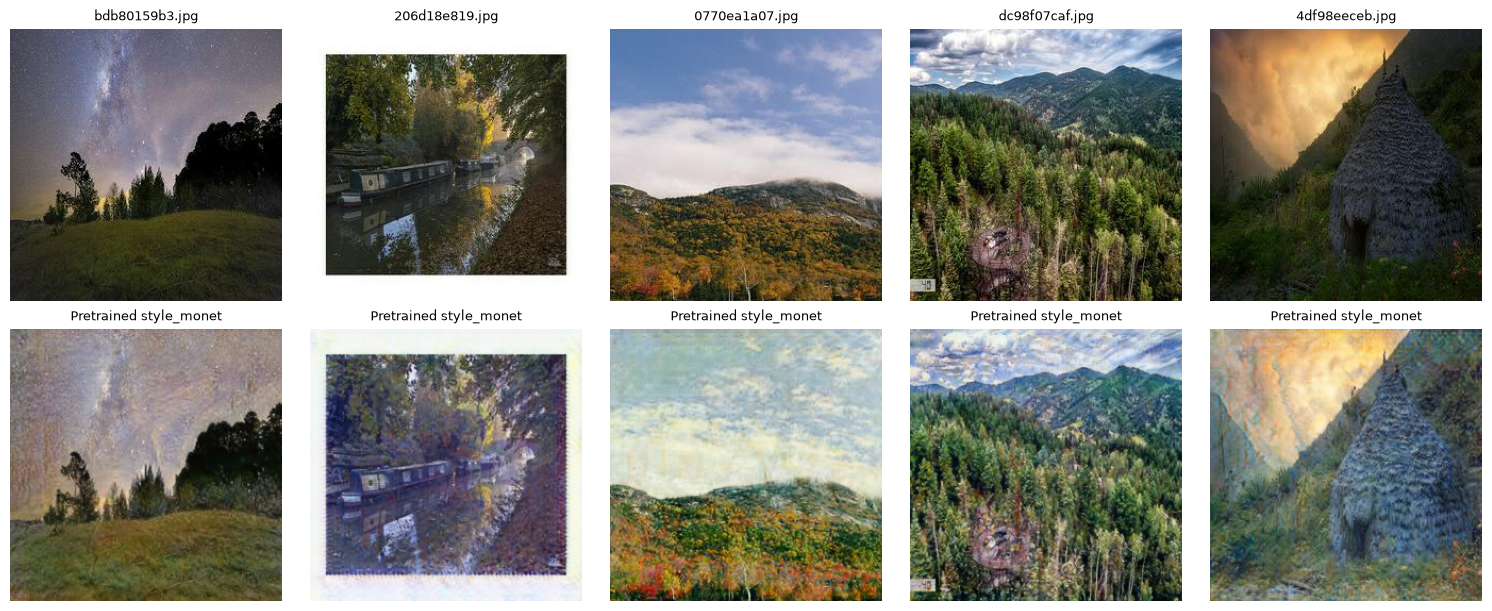

In [14]:
sample_paths = random.Random(42).sample(photo_paths, 5)
fig, axes = plt.subplots(2, 5, figsize=(15, 6), layout="constrained")
for column, image_path in enumerate(sample_paths):
    with Image.open(image_path) as original:
        axes[0, column].imshow(original.convert("RGB"))
    painting = translate_photo(generator, image_path, device)
    axes[1, column].imshow(painting)
    axes[0, column].set_title(image_path.name, fontsize=9)
    axes[1, column].set_title("Pretrained style_monet", fontsize=9)
    for row in (0, 1):
        axes[row, column].axis("off")
preview_path = output_dir / "sample_comparison.png"
fig.savefig(preview_path, dpi=120)
plt.show()


## Generate the submission output ZIP

- Transform every local photo once
- write JPGs directly into the output ZIP (to avoid thousands of output files).
- Each entry keeps its source filename.
- A temporary output ZIP becomes `images.zip` only after generation succeeds.
- Rerunning this cell regenerates the output ZIP.

In [15]:
output_zip_path = output_dir / "images.zip"
temporary_output_zip_path = output_dir / "images.partial.zip"
start = time.perf_counter()

# Storing directly into Zip:
# Generated painting -> JPEG bytes in memory (BytesIO) -> Named entry inside images.zip
# Write to temporary_output_zip_path first
with ZipFile(temporary_output_zip_path, "w", compression=ZIP_STORED) as output_zip:
    for index, image_path in enumerate(photo_paths, 1):
        painting = translate_photo(generator, image_path, device)
        if painting.size != (256, 256) or painting.mode != "RGB":
            raise ValueError(f"Invalid generated image: {image_path.name}")
        buffer = BytesIO()
        painting.save(buffer, format="JPEG", quality=95)
        output_zip.writestr(image_path.name, buffer.getvalue())
        if index % 500 == 0 or index == len(photo_paths):
            print(f"Generated {index:,}/{len(photo_paths):,} in {time.perf_counter() - start:.1f}s", flush=True)

# replace output_zip_path only after generation succeeds.
# If generation fails, any existing completed output ZIP remains unchanged.
temporary_output_zip_path.replace(output_zip_path)
print(f"Output ZIP: {output_zip_path}")


Generated 500/7,038 in 7.4s
Generated 1,000/7,038 in 17.3s
Generated 1,500/7,038 in 25.7s
Generated 2,000/7,038 in 31.9s
Generated 2,500/7,038 in 39.0s
Generated 3,000/7,038 in 44.9s
Generated 3,500/7,038 in 51.9s
Generated 4,000/7,038 in 59.8s
Generated 4,500/7,038 in 67.7s
Generated 5,000/7,038 in 74.1s
Generated 5,500/7,038 in 82.1s
Generated 6,000/7,038 in 89.0s
Generated 6,500/7,038 in 96.9s
Generated 7,000/7,038 in 106.1s
Generated 7,038/7,038 in 106.6s
Output ZIP: /Users/KurtMeehanPro/Documents/code/git/painter-myself/data/outputs/style_monet/images.zip


## Sanity Check Output
Check: 
- the output ZIP has the same number of entries as the input photos,
- none of its filenames are duplicated

In [16]:
with ZipFile(output_zip_path) as output_zip:
    names = output_zip.namelist()
    assert len(names) == len(set(names)) == len(photo_paths)
    assert set(names) == {path.name for path in photo_paths}
    assert output_zip.testzip() is None
    for name in names:
        with Image.open(BytesIO(output_zip.read(name))) as image:
            assert image.format == "JPEG" and image.mode == "RGB" and image.size == (256, 256), name
            image.load()
print(f"Validated {len(names):,} RGB JPEGs, all 256×256; output ZIP {output_zip_path.stat().st_size / 1024**2:.1f} MiB.")


Validated 7,038 RGB JPEGs, all 256×256; output ZIP 223.0 MiB.


## Baseline run results

- Executed locally on Apple MPS with the pretrained weights unchanged. 
- Generated 7,038 paintings in about 101 seconds
- validated every JPEG in the output ZIP as readable RGB at 256×256, 
- unique filenames matching all source photos.
- The output ZIP is approximately 223 MiB.
- The preview shows what looks like Monet transformations of the photos provided.
- Some edge/border artifacts remain. 
- The output ZIP and 5-photo comparison image are in `data/outputs/style_monet/`


## Attribution and license

This notebook reuses the generator implementation from the original CycleGAN authors. Their generator code is used alongside my own code in this notebook.

Attribution for the Generator Code: Jun-Yan Zhu and Taesung Park, [pytorch-CycleGAN-and-pix2pix](https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix).

See the [generator code](../scripts/cyclegan_generator.py) and [original license](../scripts/cyclegan_LICENSE.txt).
